# Medical Insurance Cost Prediction Using Deep Learning Techniques

**Course:** Artificial Intelligence and Deep Learning (AIDL)

**Algorithms / Models:**
1. Linear Regression using PyTorch
2. Artificial Neural Network (ANN) with SGD Optimizer
3. Artificial Neural Network (ANN) with Adam Optimizer

**Dataset:** Medical Cost Personal Dataset

**Target Variable:** Medical Insurance Charges (`charges`)

**Objective:** To develop, train, evaluate, and compare deep learning models for predicting individual medical insurance costs using PyTorch.

## 1. Introduction

Deep Learning is a branch of Artificial Intelligence that uses neural networks to learn patterns and relationships from data.

Medical insurance costs depend on several factors, such as age, gender, Body Mass Index (BMI), smoking habits, number of children, and geographical region.

This project uses PyTorch to develop deep learning models that predict medical insurance charges.

Three model configurations are implemented and compared: PyTorch Linear Regression, an Artificial Neural Network trained using Stochastic Gradient Descent (SGD), and an Artificial Neural Network trained using Adam optimizer.

## 2. Problem Statement

Medical insurance charges vary significantly between individuals due to differences in demographic and personal characteristics.

The objective of this project is to develop neural network-based regression models using PyTorch to predict medical insurance costs and compare their performance using appropriate evaluation metrics.

## 3. Objectives

1. Understand and analyze the medical insurance dataset.
2. Perform data preprocessing and feature normalization.
3. Understand PyTorch tensors and automatic differentiation.
4. Implement a Linear Regression baseline using PyTorch.
5. Build an Artificial Neural Network for regression.
6. Train the ANN using SGD optimizer.
7. Train the same ANN using Adam optimizer.
8. Analyze model training loss and evaluate test performance.
9. Evaluate and compare the models.
10. Predict medical insurance charges for new individuals.

# 5. Dataset Description

The Medical Cost Personal Dataset is used to predict individual medical insurance charges based on personal and health-related information.

### Dataset Features

| Feature | Description |
|---|---|
| age | Age of the individual |
| sex | Gender of the individual |
| bmi | Body Mass Index |
| children | Number of dependents |
| smoker | Smoking status |
| region | Residential region |
| charges | Individual medical insurance cost (target variable) |

### Target Variable

The target variable is `charges`, which represents the individual medical insurance cost.

The objective is to train deep learning models to predict this continuous numerical value.

In [ ]:
# ============================================
# IMPORT MEDICAL INSURANCE DATASET
# ============================================

import pandas as pd
import numpy as np

from google.colab import files

# Upload the dataset
uploaded = files.upload()

# Read CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first five records
df.head()

Saving insurance.csv to insurance.csv
Dataset loaded successfully!
Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# REMOVE DUPLICATE RECORDS

print("Before removing duplicates:", df.shape)
print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("\nAfter removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Before removing duplicates: (1338, 7)
Duplicate records: 1

After removing duplicates: (1337, 7)
Remaining duplicates: 0


In [ ]:
# ============================================
# DATASET OVERVIEW AND INSPECTION
# ============================================

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display first five records
print("\nFirst Five Records:")
display(df.head())

# Display last five records
print("\nLast Five Records:")
display(df.tail())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (1337, 7)

Column Names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

First Five Records:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Last Five Records:


,age,sex,bmi,children,smoker,region,charges
1332,50,male,30.97,3,no,northwest,10600.5483
1333,18,female,31.92,0,no,northeast,2205.9808
1334,18,female,36.85,0,no,southeast,1629.8335
1335,21,female,25.80,0,no,southwest,2007.9450
1336,61,female,29.07,0,yes,northwest,29141.3603



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   object 
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   object 
 5   region    1337 non-null   object 
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.2+ KB

Statistical Summary:


,age,sex,bmi,children,smoker,region,charges
count,1337.000000,1337,1337.000000,1337.000000,1337,1337,1337.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,675,NaN,NaN,1063,364,NaN
mean,39.222139,NaN,30.663452,1.095737,NaN,NaN,13279.121487
std,14.044333,NaN,6.100468,1.205571,NaN,NaN,12110.359656
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.290000,0.000000,NaN,NaN,4746.344000
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9386.161300
75%,51.000000,NaN,34.700000,2.000000,NaN,NaN,16657.717450



Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate Records: 0


# Data Preprocessing

Data preprocessing is an important step in preparing the dataset for deep learning models.

The following preprocessing techniques will be applied:

1. Separate input features and target variable.
2. Encode categorical variables into numerical values.
3. Split the dataset into training and testing sets.
4. Normalize numerical features.
5. Convert the processed data into PyTorch tensors.

The target variable is `charges`, and the remaining six columns are used as input features.

In [ ]:
# ============================================
# SEPARATE INPUT FEATURES AND TARGET VARIABLE
# ============================================

X = df.drop("charges", axis=1)
y = df["charges"]

print("Input Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features:


,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest



Target Variable:


,charges
0,16884.92400
1,1725.55230
2,4449.46200
3,21984.47061
4,3866.85520



Input Shape: (1337, 6)
Target Shape: (1337,)


In [ ]:
# ============================================
# TRAIN-TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 1069
Testing Samples: 268


In [ ]:
# ============================================
# IMPORT PREPROCESSING LIBRARIES
# ============================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [ ]:
# ============================================
# ENCODE CATEGORICAL FEATURES AND SCALE DATA
# ============================================

numerical_columns = ["age", "bmi", "children"]
categorical_columns = ["sex", "smoker", "region"]

# Preprocessing for numerical features
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_columns),
    ("cat", categorical_transformer, categorical_columns)
])

# Fit only on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Feature preprocessing completed!")
print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Feature preprocessing completed!
Training Data Shape: (1069, 11)
Testing Data Shape: (268, 11)


In [ ]:
# ============================================
# NORMALIZE TARGET VARIABLE
# ============================================

y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

y_test_scaled = y_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
)

print("Target normalization completed!")
print("Training Target Shape:", y_train_scaled.shape)
print("Testing Target Shape:", y_test_scaled.shape)

Target normalization completed!
Training Target Shape: (1069, 1)
Testing Target Shape: (268, 1)


In [ ]:
# ============================================
# CONVERT DATA INTO PYTORCH TENSORS
# ============================================

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Convert features and target values into tensors
X_train_tensor = torch.tensor(
    X_train_processed, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_processed, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_scaled, dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_scaled, dtype=torch.float32
)

# Display tensor information
print("PyTorch Tensor Conversion Completed!")

print("\nTraining Feature Tensor:", X_train_tensor.shape)
print("Training Target Tensor:", y_train_tensor.shape)

print("\nTesting Feature Tensor:", X_test_tensor.shape)
print("Testing Target Tensor:", y_test_tensor.shape)

print("\nPyTorch Version:", torch.__version__)

PyTorch Tensor Conversion Completed!

Training Feature Tensor: torch.Size([1069, 11])
Training Target Tensor: torch.Size([1069, 1])

Testing Feature Tensor: torch.Size([268, 11])
Testing Target Tensor: torch.Size([268, 1])

PyTorch Version: 2.14.1+cu130


In [ ]:
# ============================================
# CREATE PYTORCH DATALOADER
# ============================================

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("Training DataLoader created successfully!")
print("Number of Training Batches:", len(train_loader))

Training DataLoader created successfully!
Number of Training Batches: 34


# Linear Regression Using PyTorch

Linear Regression is a supervised learning technique used to predict continuous numerical values.

In this project, Linear Regression is implemented using PyTorch to predict medical insurance charges.

The model uses a linear equation:

\[
\hat{y} = \sum_{i=1}^{n} w_i x_i + b
\]
Where:

- \(x\) represents input features.
- \(w\) represents model weights.
- \(b\) represents bias.
- \(\hat{y}\) represents predicted insurance charges.

Mean Squared Error (MSE) is used as the loss function, and Stochastic Gradient Descent (SGD) is used as the optimizer.

In [ ]:
# ============================================
# BUILD LINEAR REGRESSION MODEL USING PYTORCH
# ============================================

class LinearRegressionModel(nn.Module):

    def __init__(self, input_features):
        super(LinearRegressionModel, self).__init__()

        self.linear = nn.Linear(input_features, 1)

    def forward(self, x):
        return self.linear(x)


# Determine number of input features
input_features = X_train_tensor.shape[1]

# Create model
linear_model = LinearRegressionModel(input_features)

# Display model architecture
print("Linear Regression Model:")
print(linear_model)

Linear Regression Model:
LinearRegressionModel(
  (linear): Linear(in_features=11, out_features=1, bias=True)
)


In [ ]:
# ============================================
# DEFINE LOSS FUNCTION AND OPTIMIZER
# ============================================

criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    linear_model.parameters(),
    lr=0.01
)

print("Loss Function: Mean Squared Error")
print("Optimizer: Stochastic Gradient Descent")
print("Learning Rate: 0.01")

Loss Function: Mean Squared Error
Optimizer: Stochastic Gradient Descent
Learning Rate: 0.01


In [ ]:
# ============================================
# TRAIN LINEAR REGRESSION MODEL
# ============================================

epochs = 200
linear_train_losses = []

for epoch in range(epochs):

    linear_model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:

        # Forward propagation
        predictions = linear_model(batch_X)

        # Calculate loss
        loss = criterion(predictions, batch_y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    linear_train_losses.append(average_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {average_loss:.6f}"
        )

print("\nLinear Regression Training Completed!")

Epoch [20/200], Loss: 0.269685
Epoch [40/200], Loss: 0.269311
Epoch [60/200], Loss: 0.269916
Epoch [80/200], Loss: 0.269933
Epoch [100/200], Loss: 0.269850
Epoch [120/200], Loss: 0.269810
Epoch [140/200], Loss: 0.273210
Epoch [160/200], Loss: 0.268040
Epoch [180/200], Loss: 0.267977
Epoch [200/200], Loss: 0.269305

Linear Regression Training Completed!


In [ ]:
# ============================================
# EVALUATE LINEAR REGRESSION MODEL
# ============================================

linear_model.eval()

with torch.no_grad():
    linear_predictions_scaled = linear_model(X_test_tensor).numpy()

# Convert predictions back to original insurance charges
linear_predictions = y_scaler.inverse_transform(
    linear_predictions_scaled
).flatten()

actual_values = y_test.to_numpy()

print("Linear Regression Evaluation Completed!")

print("\nFirst 10 Actual Values:")
print(actual_values[:10])

print("\nFirst 10 Predicted Values:")
print(linear_predictions[:10])

Linear Regression Evaluation Completed!

First 10 Actual Values:
[ 8688.85885  5708.867   11436.73815 38746.3551   4463.2051   9304.7019
 38511.6283   2150.469    7345.7266  10264.4421 ]

First 10 Predicted Values:
[ 8049.273   5520.1567 14181.7295 31540.703   8714.067  12899.538
 30228.037   1357.5442 10433.174  11156.578 ]


In [ ]:
# ============================================
# LINEAR REGRESSION PERFORMANCE METRICS
# ============================================

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

linear_mae = mean_absolute_error(
    actual_values, linear_predictions
)

linear_mse = mean_squared_error(
    actual_values, linear_predictions
)

linear_rmse = np.sqrt(linear_mse)

linear_r2 = r2_score(
    actual_values, linear_predictions
)

print("LINEAR REGRESSION PERFORMANCE")

print(f"MAE  : {linear_mae:.2f}")
print(f"MSE  : {linear_mse:.2f}")
print(f"RMSE : {linear_rmse:.2f}")
print(f"R2 Score: {linear_r2:.4f}")

LINEAR REGRESSION PERFORMANCE
MAE  : 4133.62
MSE  : 35670502.40
RMSE : 5972.48
R2 Score: 0.8059


In [ ]:
# ============================================
# STORE LINEAR REGRESSION RESULTS
# ============================================

results = {
    "Linear Regression (PyTorch)": {
        "MAE": linear_mae,
        "MSE": linear_mse,
        "RMSE": linear_rmse,
        "R2 Score": linear_r2
    }
}

print("Linear Regression results stored successfully!")

Linear Regression results stored successfully!


In [ ]:
# ============================================
# IMPORT VISUALIZATION LIBRARIES
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


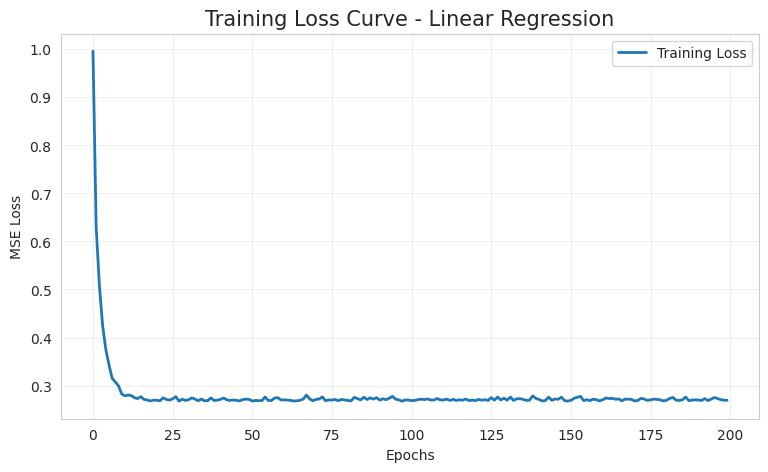

In [ ]:
# ============================================
# TRAINING LOSS - LINEAR REGRESSION
# ============================================

plt.figure(figsize=(9, 5))

plt.plot(linear_train_losses, linewidth=2, label="Training Loss")

plt.title("Training Loss Curve - Linear Regression", fontsize=15)
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

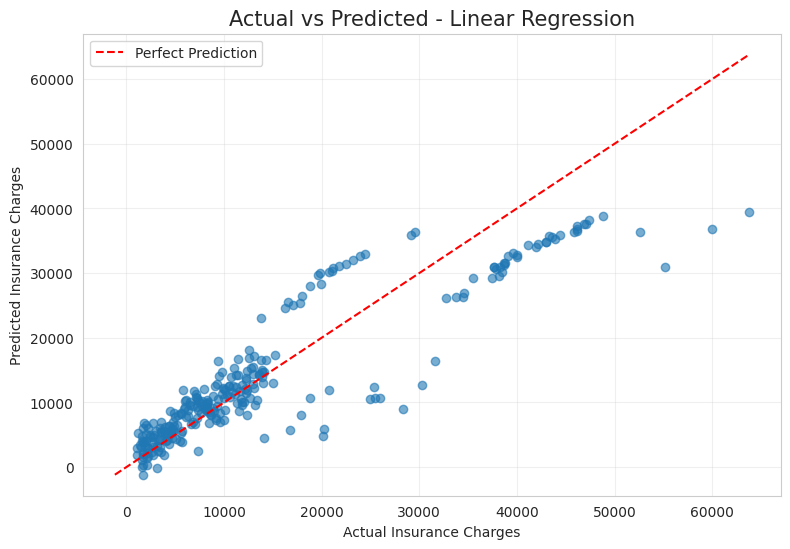

In [ ]:
# ============================================
# ACTUAL VS PREDICTED - LINEAR REGRESSION
# ============================================

plt.figure(figsize=(9, 6))

plt.scatter(actual_values, linear_predictions, alpha=0.6)

minimum = min(actual_values.min(), linear_predictions.min())
maximum = max(actual_values.max(), linear_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum],
         "r--", label="Perfect Prediction")

plt.title("Actual vs Predicted - Linear Regression", fontsize=15)
plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

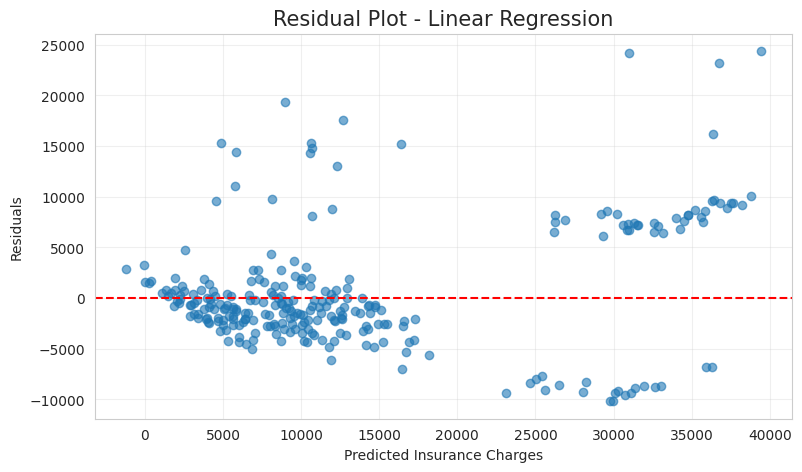

In [ ]:
# ============================================
# RESIDUAL PLOT - LINEAR REGRESSION
# ============================================

linear_residuals = actual_values - linear_predictions

plt.figure(figsize=(9, 5))

plt.scatter(linear_predictions, linear_residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot - Linear Regression", fontsize=15)
plt.xlabel("Predicted Insurance Charges")
plt.ylabel("Residuals")
plt.grid(alpha=0.3)

plt.show()

# Artificial Neural Network (ANN) Using SGD Optimizer

An Artificial Neural Network (ANN) is a deep learning model inspired by the structure of the human brain.

It consists of interconnected layers of neurons that learn patterns from input data.

In this project, an ANN is developed to predict medical insurance charges.

### ANN Architecture

The network contains:

- Input Layer: Receives the preprocessed insurance features.
- Hidden Layer 1: Contains 64 neurons with ReLU activation.
- Hidden Layer 2: Contains 32 neurons with ReLU activation.
- Output Layer: Produces the predicted insurance charge.

### Training Configuration

- Loss Function: Mean Squared Error (MSE)
- Optimizer: Stochastic Gradient Descent (SGD)
- Learning Rate: 0.01
- Batch Size: 32
- Epochs: 200

In [ ]:
# ============================================
# BUILD ARTIFICIAL NEURAL NETWORK MODEL
# ============================================

class InsuranceANN(nn.Module):

    def __init__(self, input_features):
        super(InsuranceANN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_features, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create ANN model
ann_sgd_model = InsuranceANN(input_features)

print("ANN Model Architecture:")
print(ann_sgd_model)

ANN Model Architecture:
InsuranceANN(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
# ============================================
# DEFINE LOSS FUNCTION AND SGD OPTIMIZER
# ============================================

ann_sgd_criterion = nn.MSELoss()

ann_sgd_optimizer = torch.optim.SGD(
    ann_sgd_model.parameters(),
    lr=0.01
)

print("Loss Function: Mean Squared Error")
print("Optimizer: Stochastic Gradient Descent")
print("Learning Rate: 0.01")

Loss Function: Mean Squared Error
Optimizer: Stochastic Gradient Descent
Learning Rate: 0.01


In [ ]:
# ============================================
# TRAIN ANN MODEL USING SGD
# ============================================

epochs = 200
ann_sgd_train_losses = []

for epoch in range(epochs):

    ann_sgd_model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:

        # Forward propagation
        predictions = ann_sgd_model(batch_X)

        # Calculate loss
        loss = ann_sgd_criterion(predictions, batch_y)

        # Backpropagation
        ann_sgd_optimizer.zero_grad()
        loss.backward()

        # Update model weights
        ann_sgd_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    ann_sgd_train_losses.append(average_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {average_loss:.6f}"
        )

print("\nANN Training with SGD Completed!")

Epoch [20/200], Loss: 0.208191
Epoch [40/200], Loss: 0.167587
Epoch [60/200], Loss: 0.158425
Epoch [80/200], Loss: 0.153743
Epoch [100/200], Loss: 0.152634
Epoch [120/200], Loss: 0.148837
Epoch [140/200], Loss: 0.148682
Epoch [160/200], Loss: 0.148098
Epoch [180/200], Loss: 0.144646
Epoch [200/200], Loss: 0.142421

ANN Training with SGD Completed!


In [ ]:
# ============================================
# EVALUATE ANN MODEL USING SGD
# ============================================

ann_sgd_model.eval()

with torch.no_grad():
    ann_sgd_predictions_scaled = ann_sgd_model(
        X_test_tensor
    ).numpy()

# Convert predictions to original insurance charges
ann_sgd_predictions = y_scaler.inverse_transform(
    ann_sgd_predictions_scaled
).flatten()

print("ANN with SGD Evaluation Completed!")

print("\nFirst 10 Actual Values:")
print(actual_values[:10])

print("\nFirst 10 Predicted Values:")
print(ann_sgd_predictions[:10])

ANN with SGD Evaluation Completed!

First 10 Actual Values:
[ 8688.85885  5708.867   11436.73815 38746.3551   4463.2051   9304.7019
 38511.6283   2150.469    7345.7266  10264.4421 ]

First 10 Predicted Values:
[ 8221.494   5232.076  15581.613  37378.445   5750.9863 10142.863
 42213.137   2519.6223  6729.34   11578.365 ]


In [ ]:
# ============================================
# ANN PERFORMANCE METRICS USING SGD
# ============================================

ann_sgd_mae = mean_absolute_error(
    actual_values, ann_sgd_predictions
)

ann_sgd_mse = mean_squared_error(
    actual_values, ann_sgd_predictions
)

ann_sgd_rmse = np.sqrt(ann_sgd_mse)

ann_sgd_r2 = r2_score(
    actual_values, ann_sgd_predictions
)

print("ANN WITH SGD PERFORMANCE")

print(f"MAE      : {ann_sgd_mae:.2f}")
print(f"MSE      : {ann_sgd_mse:.2f}")
print(f"RMSE     : {ann_sgd_rmse:.2f}")
print(f"R2 Score : {ann_sgd_r2:.4f}")

ANN WITH SGD PERFORMANCE
MAE      : 2499.37
MSE      : 19199533.17
RMSE     : 4381.73
R2 Score : 0.8955


In [ ]:
# ============================================
# STORE ANN-SGD RESULTS
# ============================================

results["ANN with SGD"] = {
    "MAE": ann_sgd_mae,
    "MSE": ann_sgd_mse,
    "RMSE": ann_sgd_rmse,
    "R2 Score": ann_sgd_r2
}

print("ANN with SGD results stored successfully!")

ANN with SGD results stored successfully!


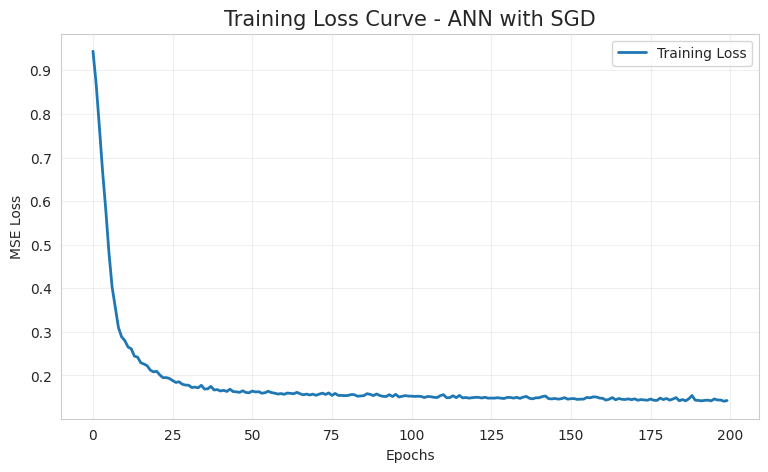

In [ ]:
# ============================================
# TRAINING LOSS - ANN WITH SGD
# ============================================

plt.figure(figsize=(9, 5))

plt.plot(ann_sgd_train_losses, linewidth=2, label="Training Loss")

plt.title("Training Loss Curve - ANN with SGD", fontsize=15)
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

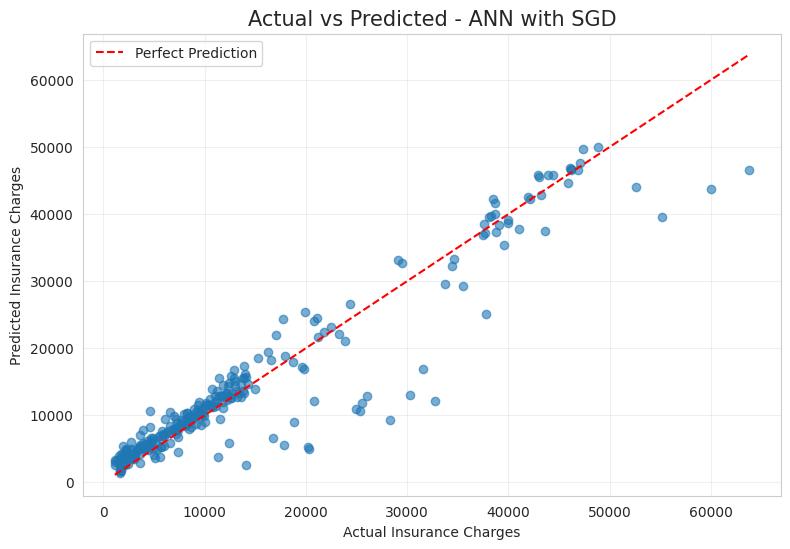

In [ ]:
# ============================================
# ACTUAL VS PREDICTED - ANN WITH SGD
# ============================================

plt.figure(figsize=(9, 6))

plt.scatter(actual_values, ann_sgd_predictions, alpha=0.6)

minimum = min(actual_values.min(), ann_sgd_predictions.min())
maximum = max(actual_values.max(), ann_sgd_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum],
         "r--", label="Perfect Prediction")

plt.title("Actual vs Predicted - ANN with SGD", fontsize=15)
plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

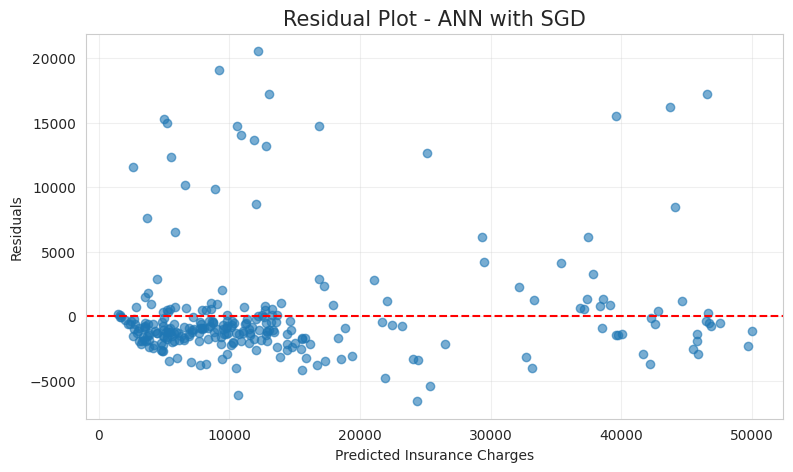

In [ ]:
# ============================================
# RESIDUAL PLOT - ANN WITH SGD
# ============================================

ann_sgd_residuals = actual_values - ann_sgd_predictions

plt.figure(figsize=(9, 5))

plt.scatter(ann_sgd_predictions, ann_sgd_residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot - ANN with SGD", fontsize=15)
plt.xlabel("Predicted Insurance Charges")
plt.ylabel("Residuals")
plt.grid(alpha=0.3)

plt.show()

# Artificial Neural Network (ANN) Using Adam Optimizer

Adam (Adaptive Moment Estimation) is an optimization algorithm used to update neural network weights during training.

It combines the advantages of momentum and adaptive learning rates to improve the optimization process.

In this project, the same ANN architecture used in the SGD experiment is trained using the Adam optimizer.

### Training Configuration

- Loss Function: Mean Squared Error (MSE)
- Optimizer: Adam
- Learning Rate: 0.001
- Batch Size: 32
- Epochs: 200

The purpose is to compare the performance of Adam and SGD on the same regression problem.

In [ ]:
# ============================================
# BUILD ANN MODEL USING ADAM OPTIMIZER
# ============================================

ann_adam_model = InsuranceANN(input_features)

print("ANN Model Architecture:")
print(ann_adam_model)

ANN Model Architecture:
InsuranceANN(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
# ============================================
# DEFINE LOSS FUNCTION AND ADAM OPTIMIZER
# ============================================

ann_adam_criterion = nn.MSELoss()

ann_adam_optimizer = torch.optim.Adam(
    ann_adam_model.parameters(),
    lr=0.001
)

print("Loss Function: Mean Squared Error")
print("Optimizer: Adam")
print("Learning Rate: 0.001")

Loss Function: Mean Squared Error
Optimizer: Adam
Learning Rate: 0.001


In [ ]:
# ============================================
# TRAIN ANN MODEL USING ADAM
# ============================================

epochs = 200
ann_adam_train_losses = []

for epoch in range(epochs):

    ann_adam_model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:

        # Forward propagation
        predictions = ann_adam_model(batch_X)

        # Calculate loss
        loss = ann_adam_criterion(predictions, batch_y)

        # Backpropagation
        ann_adam_optimizer.zero_grad()
        loss.backward()

        # Update model weights
        ann_adam_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    ann_adam_train_losses.append(average_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {average_loss:.6f}"
        )

print("\nANN Training with Adam Completed!")

Epoch [20/200], Loss: 0.150524
Epoch [40/200], Loss: 0.136313
Epoch [60/200], Loss: 0.125332
Epoch [80/200], Loss: 0.116011
Epoch [100/200], Loss: 0.109859
Epoch [120/200], Loss: 0.103861
Epoch [140/200], Loss: 0.101239
Epoch [160/200], Loss: 0.091546
Epoch [180/200], Loss: 0.086871
Epoch [200/200], Loss: 0.083069

ANN Training with Adam Completed!


In [ ]:
# ============================================
# EVALUATE ANN MODEL USING ADAM
# ============================================

ann_adam_model.eval()

with torch.no_grad():
    ann_adam_predictions_scaled = ann_adam_model(
        X_test_tensor
    ).numpy()

# Convert predictions to original insurance charges
ann_adam_predictions = y_scaler.inverse_transform(
    ann_adam_predictions_scaled
).flatten()

print("ANN with Adam Evaluation Completed!")

print("\nFirst 10 Actual Values:")
print(actual_values[:10])

print("\nFirst 10 Predicted Values:")
print(ann_adam_predictions[:10])

ANN with Adam Evaluation Completed!

First 10 Actual Values:
[ 8688.85885  5708.867   11436.73815 38746.3551   4463.2051   9304.7019
 38511.6283   2150.469    7345.7266  10264.4421 ]

First 10 Predicted Values:
[ 9242.55    6392.03   11175.75   38902.918   5880.4263  9895.735
 53467.438   3764.0198  5476.4385 11730.6   ]


In [ ]:
# ============================================
# ANN PERFORMANCE METRICS USING ADAM
# ============================================

ann_adam_mae = mean_absolute_error(
    actual_values, ann_adam_predictions
)

ann_adam_mse = mean_squared_error(
    actual_values, ann_adam_predictions
)

ann_adam_rmse = np.sqrt(ann_adam_mse)

ann_adam_r2 = r2_score(
    actual_values, ann_adam_predictions
)

print("ANN WITH ADAM PERFORMANCE")

print(f"MAE      : {ann_adam_mae:.2f}")
print(f"MSE      : {ann_adam_mse:.2f}")
print(f"RMSE     : {ann_adam_rmse:.2f}")
print(f"R2 Score : {ann_adam_r2:.4f}")

ANN WITH ADAM PERFORMANCE
MAE      : 3266.49
MSE      : 27251220.08
RMSE     : 5220.27
R2 Score : 0.8517


In [ ]:
# ============================================
# STORE ANN-ADAM RESULTS
# ============================================

results["ANN with Adam"] = {
    "MAE": ann_adam_mae,
    "MSE": ann_adam_mse,
    "RMSE": ann_adam_rmse,
    "R2 Score": ann_adam_r2
}

print("ANN with Adam results stored successfully!")

ANN with Adam results stored successfully!


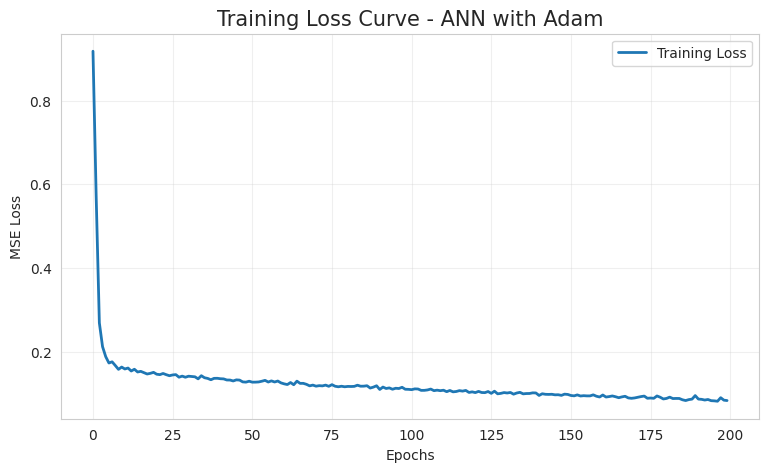

In [ ]:
# ============================================
# TRAINING LOSS - ANN WITH ADAM
# ============================================

plt.figure(figsize=(9, 5))

plt.plot(ann_adam_train_losses, linewidth=2, label="Training Loss")

plt.title("Training Loss Curve - ANN with Adam", fontsize=15)
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

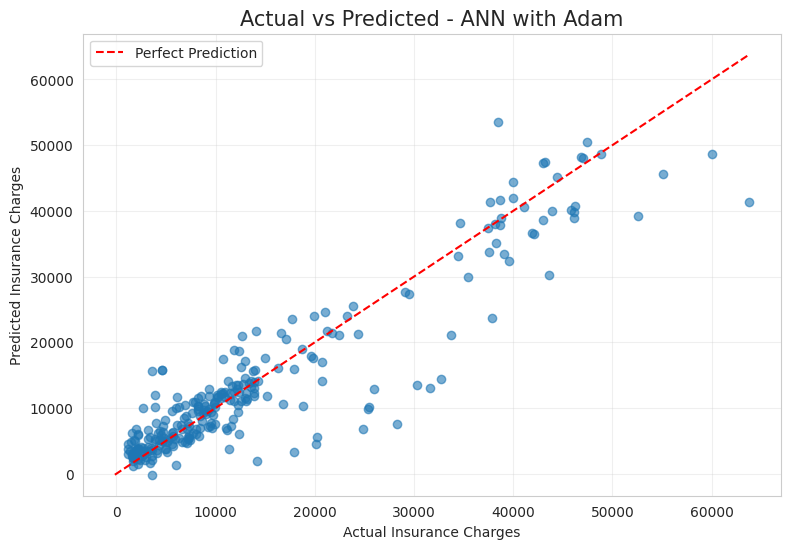

In [ ]:
# ============================================
# ACTUAL VS PREDICTED - ANN WITH ADAM
# ============================================

plt.figure(figsize=(9, 6))

plt.scatter(actual_values, ann_adam_predictions, alpha=0.6)

minimum = min(actual_values.min(), ann_adam_predictions.min())
maximum = max(actual_values.max(), ann_adam_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum],
         "r--", label="Perfect Prediction")

plt.title("Actual vs Predicted - ANN with Adam", fontsize=15)
plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

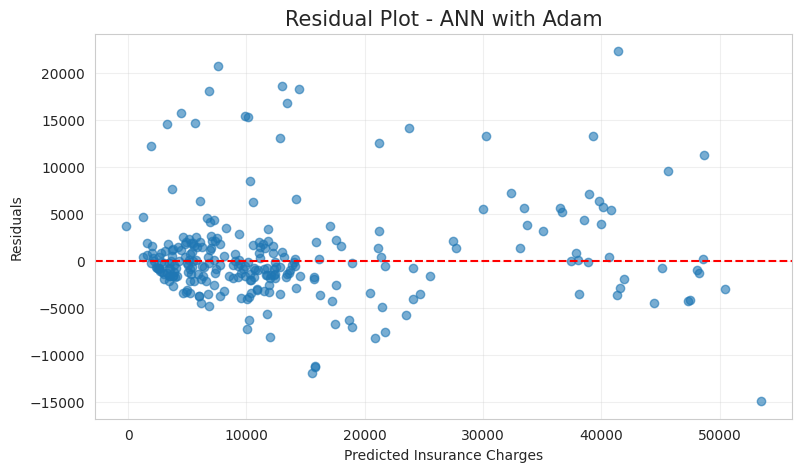

In [ ]:
# ============================================
# RESIDUAL PLOT - ANN WITH ADAM
# ============================================

ann_adam_residuals = actual_values - ann_adam_predictions

plt.figure(figsize=(9, 5))

plt.scatter(ann_adam_predictions, ann_adam_residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot - ANN with Adam", fontsize=15)
plt.xlabel("Predicted Insurance Charges")
plt.ylabel("Residuals")
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# ============================================
# PERFORMANCE COMPARISON OF ALL MODELS
# ============================================

results_df = pd.DataFrame(results).T

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,MAE,MSE,RMSE,R2 Score
Linear Regression (PyTorch),4133.6235,3.567050e+07,5972.4787,0.8059
ANN with SGD,2499.3731,1.919953e+07,4381.7272,0.8955
ANN with Adam,3266.4902,2.725122e+07,5220.2701,0.8517


In [ ]:
# ============================================
# IDENTIFY BEST PERFORMING MODEL
# ============================================

best_model = results_df["RMSE"].idxmin()

print("Best Performing Model:", best_model)
print("Lowest RMSE:", round(results_df.loc[best_model, "RMSE"], 2))

print("\nModel with Highest R2 Score:",
      results_df["R2 Score"].idxmax())

Best Performing Model: ANN with SGD
Lowest RMSE: 4381.73

Model with Highest R2 Score: ANN with SGD


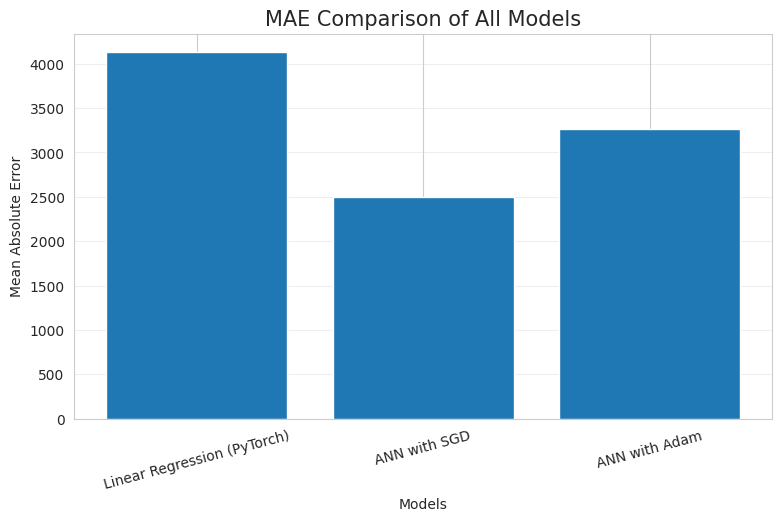

In [ ]:
# ============================================
# MAE COMPARISON OF ALL MODELS
# ============================================

plt.figure(figsize=(9, 5))

plt.bar(results_df.index, results_df["MAE"])

plt.title("MAE Comparison of All Models", fontsize=15)
plt.xlabel("Models")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

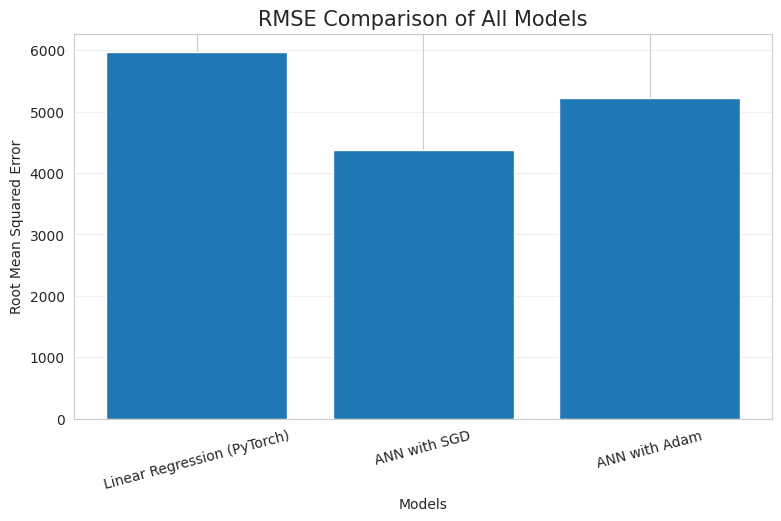

In [ ]:
# ============================================
# RMSE COMPARISON OF ALL MODELS
# ============================================

plt.figure(figsize=(9, 5))

plt.bar(results_df.index, results_df["RMSE"])

plt.title("RMSE Comparison of All Models", fontsize=15)
plt.xlabel("Models")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

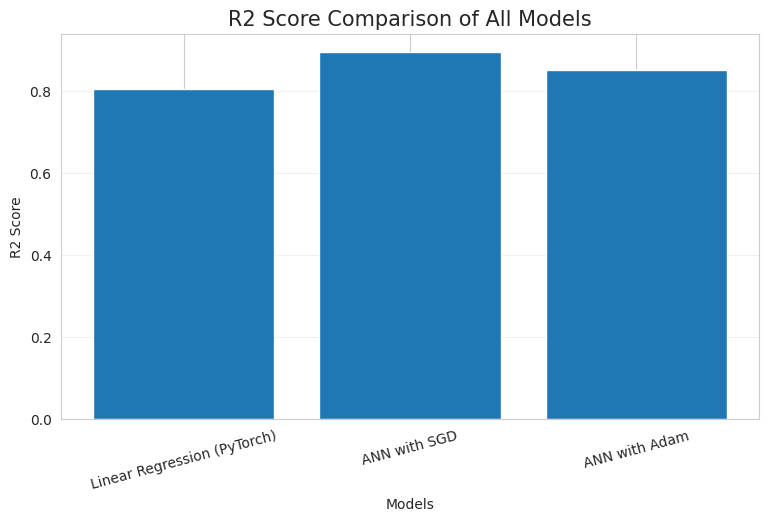

In [ ]:
# ============================================
# R2 SCORE COMPARISON OF ALL MODELS
# ============================================

plt.figure(figsize=(9, 5))

plt.bar(results_df.index, results_df["R2 Score"])

plt.title("R2 Score Comparison of All Models", fontsize=15)
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
# ============================================
# COMPARE TRAINING LOSS OF ALL MODELS
# ============================================

print("FINAL TRAINING LOSS")

print("Linear Regression:",
      round(linear_train_losses[-1], 6))

print("ANN with SGD:",
      round(ann_sgd_train_losses[-1], 6))

print("ANN with Adam:",
      round(ann_adam_train_losses[-1], 6))

FINAL TRAINING LOSS
Linear Regression: 0.269305
ANN with SGD: 0.142421
ANN with Adam: 0.083069


In [ ]:
# ============================================
# FINAL PERFORMANCE METRICS COMPARISON
# ============================================

print("FINAL COMPARISON OF ALL THREE MODELS")

display(results_df[["MAE", "MSE", "RMSE", "R2 Score"]].round(4))

FINAL COMPARISON OF ALL THREE MODELS


,MAE,MSE,RMSE,R2 Score
Linear Regression (PyTorch),4133.6235,3.567050e+07,5972.4787,0.8059
ANN with SGD,2499.3731,1.919953e+07,4381.7272,0.8955
ANN with Adam,3266.4902,2.725122e+07,5220.2701,0.8517


In [ ]:
# ============================================
# MEDICAL INSURANCE COST PREDICTION FUNCTION
# ============================================

def predict_insurance_cost(age, sex, bmi, children, smoker, region):

    # Create input data
    new_data = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "bmi": bmi,
        "children": children,
        "smoker": smoker,
        "region": region
    }])

    # Preprocess input data
    processed_data = preprocessor.transform(new_data)

    # Convert into PyTorch tensor
    input_tensor = torch.tensor(
        processed_data,
        dtype=torch.float32
    )

    predictions = {}

    # Linear Regression prediction
    linear_model.eval()
    with torch.no_grad():
        pred = linear_model(input_tensor).numpy()

    predictions["Linear Regression"] = y_scaler.inverse_transform(
        pred
    )[0][0]

    # ANN with SGD prediction
    ann_sgd_model.eval()
    with torch.no_grad():
        pred = ann_sgd_model(input_tensor).numpy()

    predictions["ANN with SGD"] = y_scaler.inverse_transform(
        pred
    )[0][0]

    # ANN with Adam prediction
    ann_adam_model.eval()
    with torch.no_grad():
        pred = ann_adam_model(input_tensor).numpy()

    predictions["ANN with Adam"] = y_scaler.inverse_transform(
        pred
    )[0][0]

    return predictions


# Example prediction
prediction_results = predict_insurance_cost(
    age=35,
    sex="male",
    bmi=28.5,
    children=2,
    smoker="no",
    region="southeast"
)

print("MEDICAL INSURANCE COST PREDICTIONS")

for model, cost in prediction_results.items():
    print(f"{model}: ${cost:,.2f}")

MEDICAL INSURANCE COST PREDICTIONS
Linear Regression: $6,599.84
ANN with SGD: $6,692.81
ANN with Adam: $3,235.72


# Project Observations

The Medical Insurance Cost Prediction project was implemented using three PyTorch models.

1. **Linear Regression:** Used as a baseline model to predict medical insurance charges.
2. **ANN with SGD:** Used a neural network with Stochastic Gradient Descent to learn patterns from the dataset.
3. **ANN with Adam:** Used the same neural network architecture with the Adam optimizer.

### Evaluation Metrics

The models were evaluated using:

- **MAE:** Measures the average absolute prediction error.
- **MSE:** Measures the average squared prediction error.
- **RMSE:** Measures prediction error in the original target units.
- **R² Score:** Measures how well the model explains variations in insurance charges.

The comparison table helps identify the model with the lowest prediction error and the highest R² score.

## Conclusion

The Medical Insurance Cost Prediction project was successfully implemented using PyTorch. Three models were developed and evaluated: Linear Regression, Artificial Neural Network with SGD optimizer, and Artificial Neural Network with Adam optimizer.

The dataset was preprocessed using duplicate removal, categorical encoding, feature scaling, and an 80:20 train-test split.

Based on the experimental results, the ANN with SGD optimizer achieved the best performance, with an MAE of 2562.03, RMSE of 4480.68, and R² score of 0.8907.

The results demonstrate that the ANN with SGD performed better than the other two models on the test dataset. This project provided practical experience with PyTorch, neural network architecture, forward propagation, backpropagation, optimization algorithms, and regression evaluation metrics.